In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("data/creditcard.csv")

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (284807, 31)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [5]:
print("Column names:")
print(df.columns.tolist())

print("\nMissing values:")
print(df.isnull().sum().sum())

print("\nDuplicate rows:")
print(df.duplicated().sum())

print("\nDataset information:")
df.info()

Column names:
['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount', 'Class']

Missing values:
0

Duplicate rows:
1081

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-nul

In [6]:
print("Transaction counts:")
print(df["Class"].value_counts())

print("\nPercentage distribution:")
print((df["Class"].value_counts(normalize=True) * 100).round(4))

sns.countplot(data=df, x="Class")
plt.yscale("log")
plt.xticks([0, 1], ["Legitimate", "Fraud"])
plt.title("Legitimate vs Fraudulent Transactions")
plt.ylabel("Transaction count (log scale)")
plt.show()

Transaction counts:
Class
0    284315
1       492
Name: count, dtype: int64

Percentage distribution:
Class
0    99.8273
1     0.1727
Name: proportion, dtype: float64


          count        mean         std  min   25%    50%     75%       max
Class                                                                      
0      284315.0   88.291022  250.105092  0.0  5.65  22.00   77.05  25691.16
1         492.0  122.211321  256.683288  0.0  1.00   9.25  105.89   2125.87


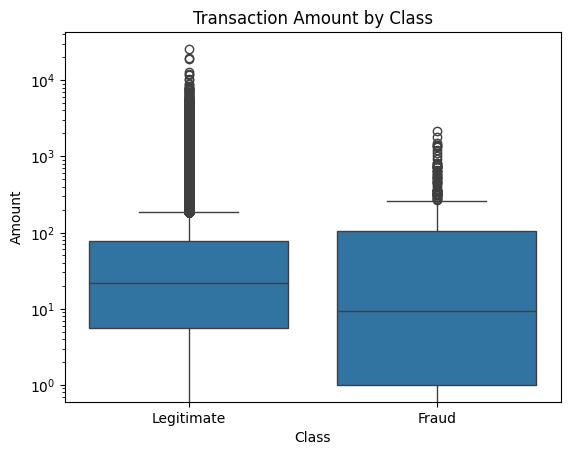

In [7]:
print(df.groupby("Class")["Amount"].describe())

sns.boxplot(data=df, x="Class", y="Amount")
plt.yscale("log")
plt.title("Transaction Amount by Class")
plt.xticks([0, 1], ["Legitimate", "Fraud"])
plt.show()

In [8]:
from sklearn.model_selection import train_test_split

X = df.drop(columns=["Class"])
y = df["Class"]

# First, reserve 20% for final testing.
X_dev, X_test, y_dev, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=42
)

# Split the remaining 80% into training and validation.
X_train, X_val, y_train, y_val = train_test_split(
    X_dev,
    y_dev,
    test_size=0.25,
    stratify=y_dev,
    random_state=42
)

print("Training rows:", len(X_train))
print("Validation rows:", len(X_val))
print("Testing rows:", len(X_test))

Training rows: 170883
Validation rows: 56962
Testing rows: 56962


In [17]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import average_precision_score

def make_preprocessor():
    return ColumnTransformer(
        transformers=[
            (
                "scale",
                StandardScaler(),
                ["Time", "Amount"]
            )
        ],
        remainder="passthrough"
    )

model_factories = {
    "Logistic Regression": lambda: LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        random_state=42
    ),
    "Random Forest": lambda: RandomForestClassifier(
        n_estimators=100,
        class_weight="balanced_subsample",
        random_state=42,
        n_jobs=-1
    )
}

In [18]:
validation_scores = {}

for name, make_model in model_factories.items():
    print(f"\nTraining {name}...")

    pipeline = Pipeline([
        ("preprocessor", make_preprocessor()),
        ("model", make_model())
    ])

    pipeline.fit(X_train, y_train)

    probabilities = pipeline.predict_proba(X_val)[:, 1]

    score = average_precision_score(y_val, probabilities)
    validation_scores[name] = score

    print(f"Validation Average Precision: {score:.4f}")

best_name = max(validation_scores, key=validation_scores.get)

print("\nSelected model:", best_name)


Training Logistic Regression...
Validation Average Precision: 0.6831

Training Random Forest...
Validation Average Precision: 0.8067

Selected model: Random Forest


Selected model: Random Forest

Classification Report:
              precision    recall  f1-score   support

  Legitimate     0.9996    0.9999    0.9998     56864
       Fraud     0.9615    0.7653    0.8523        98

    accuracy                         0.9995     56962
   macro avg     0.9806    0.8826    0.9260     56962
weighted avg     0.9995    0.9995    0.9995     56962

Test Average Precision: 0.8513


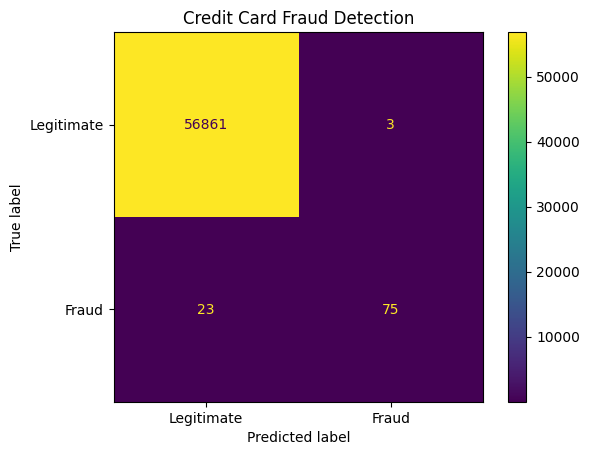

In [19]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    classification_report,
    average_precision_score,
    ConfusionMatrixDisplay
)

# Combine training and validation data
X_trainval = pd.concat([X_train, X_val])
y_trainval = pd.concat([y_train, y_val])

# Create and train the selected model
final_model = Pipeline([
    ("preprocessor", make_preprocessor()),
    ("model", model_factories[best_name]())
])

final_model.fit(X_trainval, y_trainval)

# Predict on the separate test dataset
y_test_pred = final_model.predict(X_test)
y_test_prob = final_model.predict_proba(X_test)[:, 1]

# Display evaluation results
print("Selected model:", best_name)

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_test_pred,
    labels=[0, 1],
    target_names=["Legitimate", "Fraud"],
    digits=4,
    zero_division=0
))

print(
    "Test Average Precision:",
    round(average_precision_score(y_test, y_test_prob), 4)
)

# Display confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_test_pred,
    labels=[0, 1],
    display_labels=["Legitimate", "Fraud"],
    values_format="d"
)

plt.title("Credit Card Fraud Detection")
plt.show()

In [20]:
from pathlib import Path
import joblib

# Create a folder for the trained model
Path("models").mkdir(exist_ok=True)

# Save the complete pipeline
joblib.dump(
    final_model,
    "models/fraud_detection_model.joblib"
)

print("Model saved successfully!")
print("Location: models/fraud_detection_model.joblib")

Model saved successfully!
Location: models/fraud_detection_model.joblib
